### Overview

[`XArray`](https://docs.xarray.dev/en/stable/) has emerged as one of the key Python libraries to work with gridded raster datasets. It can natively handle time-series data making it ideal for working with Remote Sensing datasets. It builds on NumPy/Pandas for fast arrays/indexing and is orders of magnitude faster than other Python libraries like `rasterio`. It has a growing ecosystem of extensions `rioxarray`, `xarray-spatial`, `XEE` and more allowing it to be used for geospatial analysis. XArray offers the flexibility to seamlessly work with local datasets along with cloud-hosted datasets in a variety of optimized data formats.

In this section, we will learn about XArray basics and learn how to work with a time-series of Sentinel-2 satellite imagery to create and visualize a median composite image.

### Setup

Determine our runtime environment.

In [1]:
import os

if 'COLAB_RELEASE_TAG' in os.environ:
    environment = 'colab'
    if os.environ.get('VERTEX_PRODUCT') == 'COLAB_ENTERPRISE':
        environment = 'colab_enterprise'
else:
    environment = 'local'

print(f'Environment: {environment}')

Environment: colab


If we are on Google Colab, install the required packages. Local runtimes are expected to have the packages already installed.

In [2]:
%%capture
if environment in ['colab', 'colab_enterprise']:
      !pip install pystac-client odc-stac rioxarray dask['distributed'] botocore

Import all required libraries. Make sure to import everything at the beginning as certain Xarray extensions are activated on import and registers certain accesors, like `.rio` and `.odc` for Xarray objects.

In [3]:
import matplotlib.pyplot as plt
import os
import pystac_client
import rioxarray as rxr
import xarray as xr
from odc.stac import configure_s3_access, stac_load

### Get Satellite Imagery

We define a location and time of interest to get some satellite imagery.

In [4]:
latitude = 27.163
longitude = 82.608
year = 2023

Let's use Element84 search endpoint to look for items from the sentinel-2-l2a collection on AWS.

In [5]:
catalog = pystac_client.Client.open(
    'https://earth-search.aws.element84.com/v1')

# Configure settings for reading from Earth Search STAC
configure_s3_access(
    aws_unsigned=True,
)

# Define a small bounding box around the chosen point
km2deg = 1.0 / 111
x, y = (longitude, latitude)
r = 1 * km2deg  # radius in degrees
bbox = (x - r, y - r, x + r, y + r)

search = catalog.search(
    collections=['sentinel-2-c1-l2a'],
    bbox=bbox,
    datetime=f'{year}',
    query={'eo:cloud_cover': {'lt': 30}},
)
items = search.item_collection()

Load the matching images as a XArray Dataset.

In [6]:
ds = stac_load(
    items,
    bands=['red', 'green', 'blue', 'nir'],
    resolution=10,
    crs='utm',
    bbox=bbox,
    chunks={},  # <-- use Dask
    groupby='solar_day',
)

In [7]:
%%time
ds = ds.compute()

CPU times: user 5.84 s, sys: 592 ms, total: 6.43 s
Wall time: 29.4 s


### XArray Terminology

We now have a `xarray.Dataset` object. Let's understand what is contained in a Dataset.

* *Variables*: This is similar to a band in a raster dataset. Each variable contains an array of values.
* *Dimensions*: This is similar to number of array axes.
* *Coordinates*: These are the labels for values in each dimension.
* *Attributes*: This is the metadata associated with the dataset.

<img src='https://courses.spatialthoughts.com/images/common/xarray_terminology.png' width=800/>

Let's see our `Dataset` and see what variables, coordinates and dimensions it contains.

In [8]:
ds

<xarray.Dataset> Size: 21MB
Dimensions:      (y: 202, x: 182, time: 70)
Coordinates:
  * y            (y) float64 2kB 3.007e+06 3.007e+06 ... 3.005e+06 3.005e+06
  * x            (x) float64 1kB 6.584e+05 6.584e+05 ... 6.602e+05 6.602e+05
  * time         (time) datetime64[ns] 560B 2023-01-13T05:21:06.880000 ... 20...
    spatial_ref  int32 4B 32644
Data variables:
    red          (time, y, x) uint16 5MB 7592 7548 7388 7236 ... 2038 2198 2240
    green        (time, y, x) uint16 5MB 7308 7260 7188 7064 ... 2204 2192 2188
    blue         (time, y, x) uint16 5MB 7332 7152 7112 7036 ... 1947 2010 2040
    nir          (time, y, x) uint16 5MB 8076 7996 7840 7708 ... 3978 3708 3352

A Dataset consists of one or more `xarray.DataArray` object. This is the main object that consists of a single variable with dimension names, coordinates and attributes. You can access each variable using `dataset[variable_name]` or `dataset.varaible_name` syntax.

In [9]:
da = ds['red']
da

<xarray.DataArray 'red' (time: 70, y: 202, x: 182)> Size: 5MB
array([[[7592, 7548, 7388, ..., 7620, 7588, 7640],
        [7392, 7248, 7128, ..., 7632, 7680, 7744],
        [7164, 6976, 6844, ..., 7688, 7700, 7772],
        ...,
        [6512, 6560, 6592, ..., 8224, 8216, 8128],
        [6416, 6500, 6556, ..., 8160, 8152, 8128],
        [6396, 6528, 6604, ..., 7996, 7976, 7880]],

       [[1786, 1720, 1689, ..., 1888, 1772, 1808],
        [1834, 1752, 1724, ..., 1820, 1677, 1736],
        [1884, 1782, 1780, ..., 1742, 1652, 1694],
        ...,
        [1626, 1662, 1698, ..., 1878, 1824, 1724],
        [1656, 1690, 1641, ..., 1811, 1926, 2042],
        [1700, 1664, 1572, ..., 1836, 1922, 2044]],

       [[1585, 1530, 1465, ..., 1648, 1493, 1516],
        [1634, 1508, 1483, ..., 1590, 1459, 1523],
        [1736, 1616, 1518, ..., 1602, 1492, 1568],
        ...,
...
        [   0,    0,    0, ..., 1816, 2152, 2354],
        [   0,    0,    0, ..., 1892, 2208, 2374],
        [   0,    0,    0, ..., 2094, 2102, 2156]],

       [[2318, 2258, 2078, ..., 1702, 1648, 1728],
        [2064, 2160, 1990, ..., 1666, 1604, 1718],
        [1778, 1906, 1808, ..., 1714, 1692, 1726],
        ...,
        [2002, 2042, 1971, ..., 1700, 2070, 2146],
        [1980, 2032, 2011, ..., 1722, 2132, 2124],
        [1880, 2000, 1930, ..., 1944, 2060, 1998]],

       [[   0,    0,    0, ..., 1821, 1762, 1830],
        [   0,    0,    0, ..., 1818, 1750, 1814],
        [   0,    0,    0, ..., 1776, 1816, 1832],
        ...,
        [2078, 2092, 2058, ..., 1899, 2152, 2302],
        [2080, 2084, 2090, ..., 1936, 2188, 2290],
        [1970, 2030, 2034, ..., 2038, 2198, 2240]]],
      shape=(70, 202, 182), dtype=uint16)
Coordinates:
  * time         (time) datetime64[ns] 560B 2023-01-13T05:21:06.880000 ... 20...
  * y            (y) float64 2kB 3.007e+06 3.007e+06 ... 3.005e+06 3.005e+06
  * x            (x) float64 1kB 6.584e+05 6.584e+05 ... 6.602e+05 6.602e+05
    spatial_ref  int32 4B 32644
Attributes:
    nodata:   0

### Selecting Data

XArray provides a very powerful way to select subsets of data, using similar framework as Pandas. Similar to Panda's `loc` and `iloc` methods, XArray provides `sel` and `isel` methods. Since DataArray dimensions have names, these methods allow you to specify which dimension to query.

Let's select the image for the last time step. Since we know the index (-1) of the data we can use `isel` method.

In [10]:
da.isel(time=-1)

<xarray.DataArray 'red' (y: 202, x: 182)> Size: 74kB
array([[   0,    0,    0, ..., 1821, 1762, 1830],
       [   0,    0,    0, ..., 1818, 1750, 1814],
       [   0,    0,    0, ..., 1776, 1816, 1832],
       ...,
       [2078, 2092, 2058, ..., 1899, 2152, 2302],
       [2080, 2084, 2090, ..., 1936, 2188, 2290],
       [1970, 2030, 2034, ..., 2038, 2198, 2240]],
      shape=(202, 182), dtype=uint16)
Coordinates:
  * y            (y) float64 2kB 3.007e+06 3.007e+06 ... 3.005e+06 3.005e+06
  * x            (x) float64 1kB 6.584e+05 6.584e+05 ... 6.602e+05 6.602e+05
    spatial_ref  int32 4B 32644
    time         datetime64[ns] 8B 2023-12-26T05:11:10.219000
Attributes:
    nodata:   0

You can call `.values` on a DataArray to get an array of the values.

In [11]:
da.isel(time=-1).values

array([[   0,    0,    0, ..., 1821, 1762, 1830],
       [   0,    0,    0, ..., 1818, 1750, 1814],
       [   0,    0,    0, ..., 1776, 1816, 1832],
       ...,
       [2078, 2092, 2058, ..., 1899, 2152, 2302],
       [2080, 2084, 2090, ..., 1936, 2188, 2290],
       [1970, 2030, 2034, ..., 2038, 2198, 2240]],
      shape=(202, 182), dtype=uint16)

You can query for a values at using multiple dimensions.

In [12]:
da.isel(time=-1, x=-1, y=-1).values

array(2240, dtype=uint16)

You can use `.item()` on any output to get the standard Python scalar object.

In [13]:
da.isel(time=-1, x=-1, y=-1).values.item()

2240

We can also specify a value to query using the `sel()` method.

Let's see what are the values of `time` variable.

In [14]:
dates = da.time.values
dates

array(['2023-01-13T05:21:06.880000000', '2023-01-18T05:21:06.614000000',
       '2023-01-23T05:21:05.552000000', '2023-02-07T05:21:07.419000000',
       '2023-02-09T05:11:12.073000000', '2023-02-12T05:21:07.542000000',
       '2023-02-14T05:11:11.668000000', '2023-02-19T05:11:10.303000000',
       '2023-02-22T05:21:06.867000000', '2023-03-01T05:11:10.619000000',
       '2023-03-04T05:21:06.040000000', '2023-03-06T05:11:16.188000000',
       '2023-03-09T05:21:13.261000000', '2023-03-11T05:11:08.720000000',
       '2023-03-24T05:21:07.945000000', '2023-03-26T05:11:16.033000000',
       '2023-04-03T05:21:08.616000000', '2023-04-05T05:11:16.355000000',
       '2023-04-08T05:21:11.786000000', '2023-04-10T05:11:13.434000000',
       '2023-04-13T05:21:09.401000000', '2023-04-18T05:21:11.018000000',
       '2023-04-23T05:21:08.563000000', '2023-04-25T05:11:15.158000000',
       '2023-05-05T05:11:15.867000000', '2023-05-10T05:11:12.717000000',
       '2023-05-13T05:21:09.142000000', '2023-05-18

We can query using the value of a coordinate using the `sel()` method.

In [15]:
da.sel(time='2023-11-16T05:11:11.658000000')

<xarray.DataArray 'red' (y: 202, x: 182)> Size: 74kB
array([[2620, 2574, 2540, ..., 2470, 2494, 2636],
       [2632, 2594, 2538, ..., 2448, 2438, 2556],
       [2632, 2642, 2562, ..., 2470, 2470, 2570],
       ...,
       [2496, 2410, 2466, ..., 2542, 2544, 2614],
       [2480, 2422, 2448, ..., 2544, 2508, 2522],
       [2572, 2516, 2552, ..., 2598, 2488, 2498]],
      shape=(202, 182), dtype=uint16)
Coordinates:
  * y            (y) float64 2kB 3.007e+06 3.007e+06 ... 3.005e+06 3.005e+06
  * x            (x) float64 1kB 6.584e+05 6.584e+05 ... 6.602e+05 6.602e+05
    spatial_ref  int32 4B 32644
    time         datetime64[ns] 8B 2023-11-16T05:11:11.658000
Attributes:
    nodata:   0

The `sel()` method also support nearest neighbor lookups. This is useful when you do not know the exact label of the dimension, but want to find the closest one.

> Tip: You can use `interp()` instead of `sel()` to interpolate the value instead of closest lookup.

In [16]:
da.sel(time='2023-01-01', method='nearest')

<xarray.DataArray 'red' (y: 202, x: 182)> Size: 74kB
array([[7592, 7548, 7388, ..., 7620, 7588, 7640],
       [7392, 7248, 7128, ..., 7632, 7680, 7744],
       [7164, 6976, 6844, ..., 7688, 7700, 7772],
       ...,
       [6512, 6560, 6592, ..., 8224, 8216, 8128],
       [6416, 6500, 6556, ..., 8160, 8152, 8128],
       [6396, 6528, 6604, ..., 7996, 7976, 7880]],
      shape=(202, 182), dtype=uint16)
Coordinates:
  * y            (y) float64 2kB 3.007e+06 3.007e+06 ... 3.005e+06 3.005e+06
  * x            (x) float64 1kB 6.584e+05 6.584e+05 ... 6.602e+05 6.602e+05
    spatial_ref  int32 4B 32644
    time         datetime64[ns] 8B 2023-01-13T05:21:06.880000
Attributes:
    nodata:   0

We can query using partial data strings for broad matches as well.

In [17]:
da.sel(time='2023-01')

<xarray.DataArray 'red' (time: 3, y: 202, x: 182)> Size: 221kB
array([[[7592, 7548, 7388, ..., 7620, 7588, 7640],
        [7392, 7248, 7128, ..., 7632, 7680, 7744],
        [7164, 6976, 6844, ..., 7688, 7700, 7772],
        ...,
        [6512, 6560, 6592, ..., 8224, 8216, 8128],
        [6416, 6500, 6556, ..., 8160, 8152, 8128],
        [6396, 6528, 6604, ..., 7996, 7976, 7880]],

       [[1786, 1720, 1689, ..., 1888, 1772, 1808],
        [1834, 1752, 1724, ..., 1820, 1677, 1736],
        [1884, 1782, 1780, ..., 1742, 1652, 1694],
        ...,
        [1626, 1662, 1698, ..., 1878, 1824, 1724],
        [1656, 1690, 1641, ..., 1811, 1926, 2042],
        [1700, 1664, 1572, ..., 1836, 1922, 2044]],

       [[1585, 1530, 1465, ..., 1648, 1493, 1516],
        [1634, 1508, 1483, ..., 1590, 1459, 1523],
        [1736, 1616, 1518, ..., 1602, 1492, 1568],
        ...,
        [1536, 1599, 1593, ..., 1714, 1753, 1948],
        [1593, 1616, 1585, ..., 1726, 1788, 1928],
        [1574, 1585, 1567, ..., 1819, 1768, 1821]]],
      shape=(3, 202, 182), dtype=uint16)
Coordinates:
  * time         (time) datetime64[ns] 24B 2023-01-13T05:21:06.880000 ... 202...
  * y            (y) float64 2kB 3.007e+06 3.007e+06 ... 3.005e+06 3.005e+06
  * x            (x) float64 1kB 6.584e+05 6.584e+05 ... 6.602e+05 6.602e+05
    spatial_ref  int32 4B 32644
Attributes:
    nodata:   0

The `sel()` method also allows specifying range of values using Python's built-in `slice()` function. The code below will select all observations during January 2023.

In [18]:
da.sel(time=slice('2023-01-01', '2023-01-31'))

<xarray.DataArray 'red' (time: 3, y: 202, x: 182)> Size: 221kB
array([[[7592, 7548, 7388, ..., 7620, 7588, 7640],
        [7392, 7248, 7128, ..., 7632, 7680, 7744],
        [7164, 6976, 6844, ..., 7688, 7700, 7772],
        ...,
        [6512, 6560, 6592, ..., 8224, 8216, 8128],
        [6416, 6500, 6556, ..., 8160, 8152, 8128],
        [6396, 6528, 6604, ..., 7996, 7976, 7880]],

       [[1786, 1720, 1689, ..., 1888, 1772, 1808],
        [1834, 1752, 1724, ..., 1820, 1677, 1736],
        [1884, 1782, 1780, ..., 1742, 1652, 1694],
        ...,
        [1626, 1662, 1698, ..., 1878, 1824, 1724],
        [1656, 1690, 1641, ..., 1811, 1926, 2042],
        [1700, 1664, 1572, ..., 1836, 1922, 2044]],

       [[1585, 1530, 1465, ..., 1648, 1493, 1516],
        [1634, 1508, 1483, ..., 1590, 1459, 1523],
        [1736, 1616, 1518, ..., 1602, 1492, 1568],
        ...,
        [1536, 1599, 1593, ..., 1714, 1753, 1948],
        [1593, 1616, 1585, ..., 1726, 1788, 1928],
        [1574, 1585, 1567, ..., 1819, 1768, 1821]]],
      shape=(3, 202, 182), dtype=uint16)
Coordinates:
  * time         (time) datetime64[ns] 24B 2023-01-13T05:21:06.880000 ... 202...
  * y            (y) float64 2kB 3.007e+06 3.007e+06 ... 3.005e+06 3.005e+06
  * x            (x) float64 1kB 6.584e+05 6.584e+05 ... 6.602e+05 6.602e+05
    spatial_ref  int32 4B 32644
Attributes:
    nodata:   0

### Aggregating Data

A very-powerful feature of XArray is the ability to easily aggregate data across dimensions - making it ideal for many remote sensing analysis. Let's create a median composite from all the individual images.

We apply the `.median()` aggregation across the `time` dimension.

In [19]:
median = ds.median(dim='time')
median

<xarray.Dataset> Size: 1MB
Dimensions:      (y: 202, x: 182)
Coordinates:
  * y            (y) float64 2kB 3.007e+06 3.007e+06 ... 3.005e+06 3.005e+06
  * x            (x) float64 1kB 6.584e+05 6.584e+05 ... 6.602e+05 6.602e+05
    spatial_ref  int32 4B 32644
Data variables:
    red          (y, x) float64 294kB 2.144e+03 2.134e+03 ... 2.253e+03
    green        (y, x) float64 294kB 1.932e+03 1.942e+03 ... 2.154e+03 2.14e+03
    blue         (y, x) float64 294kB 1.744e+03 1.76e+03 ... 1.905e+03 1.93e+03
    nir          (y, x) float64 294kB 3.362e+03 3.371e+03 ... 3.741e+03

### Visualizing Data

XArray provides a `plot.imshow()` method based on Matplotlib to plot DataArrays.

Reference : [xarray.plot.imshow ](https://docs.xarray.dev/en/stable/generated/xarray.plot.imshow.html)

To visualize our Dataset, we first convert it to a DataArray using the `to_array()` method. All the variables will be converted to a new dimension. Since our variables are image bands, we give the name of the new dimesion as `band`.

In [20]:
median_da = median.to_array('band')
median_da

<xarray.DataArray (band: 4, y: 202, x: 182)> Size: 1MB
array([[[2144. , 2134. , 2090. , ..., 2373. , 2291. , 2382. ],
        [2035. , 2145. , 2063. , ..., 2285. , 2129. , 2366. ],
        [1874.5, 1983.5, 1986. , ..., 2332. , 2173. , 2304. ],
        ...,
        [2122. , 2124. , 2185. , ..., 2153. , 2230. , 2423. ],
        [2126. , 2113. , 2199. , ..., 2163. , 2239. , 2379. ],
        [2355. , 2190. , 2281. , ..., 2206. , 2198. , 2253. ]],

       [[1932.5, 1942. , 1945. , ..., 2195. , 2135. , 2203. ],
        [1977.5, 1985.5, 1940.5, ..., 2131. , 2043. , 2204. ],
        [1960. , 1987. , 1943.5, ..., 2192. , 2075. , 2260. ],
        ...,
        [2053. , 2142. , 2194. , ..., 2166. , 2195. , 2347. ],
        [2124. , 2166. , 2229. , ..., 2156. , 2208. , 2298. ],
        [2185. , 2121. , 2255. , ..., 2188. , 2154. , 2140. ]],

       [[1744.5, 1760.5, 1755.5, ..., 2071. , 2037. , 2012. ],
        [1771.5, 1756.5, 1735. , ..., 1949. , 1825. , 1979. ],
        [1756.5, 1757.5, 1749. , ..., 1941.5, 1789. , 2016.5],
        ...,
        [1872.5, 1942. , 1964.5, ..., 1897. , 2009. , 2160. ],
        [1937. , 1975. , 2010.5, ..., 1928.5, 1967. , 2024. ],
        [1930.5, 1932. , 2053. , ..., 1979.5, 1905. , 1930. ]],

       [[3362. , 3371. , 3295. , ..., 3753.5, 3872. , 3946. ],
        [3371. , 3389. , 3287. , ..., 3540. , 3631. , 3909. ],
        [3366. , 3370. , 3189. , ..., 3734. , 3860. , 3836. ],
        ...,
        [3746. , 3756. , 3864. , ..., 3637. , 3516. , 3528. ],
        [3821. , 3789. , 3869. , ..., 3542. , 3883. , 3656. ],
        [3841. , 3873. , 3835. , ..., 3901.5, 4087. , 3741. ]]],
      shape=(4, 202, 182))
Coordinates:
  * band         (band) object 32B 'red' 'green' 'blue' 'nir'
  * y            (y) float64 2kB 3.007e+06 3.007e+06 ... 3.005e+06 3.005e+06
  * x            (x) float64 1kB 6.584e+05 6.584e+05 ... 6.602e+05 6.602e+05
    spatial_ref  int32 4B 32644

The easy way to visualize the data without the outliers is to pass the parameter `robust=True`. This will use the 2nd and 98th percentiles of the data to compute the color limits. We also specify the `set_aspect('equal')` to ensure the original aspect ratio is maintained and the image is not stretched.

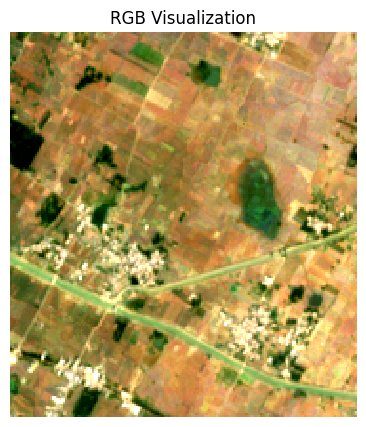

In [21]:
fig, ax = plt.subplots(1, 1)
fig.set_size_inches(5,5)
median_da.sel(band=['red', 'green', 'blue']).plot.imshow(
    ax=ax,
    robust=True)
ax.set_title('RGB Visualization')
ax.set_axis_off()
ax.set_aspect('equal')
plt.show()

### Exercise

Display the median composite for the month of May.

The snippet below takes our time-series and aggregate it to a monthly median composites `groupby()` method.

In [22]:
monthly = ds.groupby('time.month').median(dim='time')
monthly

<xarray.Dataset> Size: 14MB
Dimensions:      (month: 12, y: 202, x: 182)
Coordinates:
  * month        (month) int64 96B 1 2 3 4 5 6 7 8 9 10 11 12
  * y            (y) float64 2kB 3.007e+06 3.007e+06 ... 3.005e+06 3.005e+06
  * x            (x) float64 1kB 6.584e+05 6.584e+05 ... 6.602e+05 6.602e+05
    spatial_ref  int32 4B 32644
Data variables:
    red          (month, y, x) float64 4MB 1.786e+03 1.72e+03 ... 2.225e+03
    green        (month, y, x) float64 4MB 2.006e+03 1.976e+03 ... 2.191e+03
    blue         (month, y, x) float64 4MB 1.842e+03 1.802e+03 ... 2.016e+03
    nir          (month, y, x) float64 4MB 3.754e+03 3.972e+03 ... 3.232e+03

You now have a new dimension named `month`. Start your exercise by first converting the Dataset to a DataArray. Then extract the data for the chosen month using `sel()` method and plot it.

In [23]:
#Converting to a DataArray:
monthly_arr = monthly.to_array('band')
monthly_arr

<xarray.DataArray (band: 4, month: 12, y: 202, x: 182)> Size: 14MB
array([[[[1786. , 1720. , 1689. , ..., 1888. , 1772. , 1808. ],
         [1834. , 1752. , 1724. , ..., 1820. , 1677. , 1736. ],
         [1884. , 1782. , 1780. , ..., 1742. , 1652. , 1694. ],
         ...,
         [1626. , 1662. , 1698. , ..., 1878. , 1824. , 1948. ],
         [1656. , 1690. , 1641. , ..., 1811. , 1926. , 2042. ],
         [1700. , 1664. , 1572. , ..., 1836. , 1922. , 2044. ]],

        [[ 637. ,  620. ,  636. , ..., 1425. , 1409. , 1434.5],
         [ 649. ,  642.5,  624. , ..., 1415. , 1389. , 1414. ],
         [ 676. ,  669.5,  624. , ..., 1448.5, 1429. , 1435. ],
         ...,
         [1420. , 1537.5, 1518. , ..., 1748.5, 1856. , 2116. ],
         [1542. , 1558. , 1484. , ..., 1847. , 1923. , 2039. ],
         [1485.5, 1467. , 1454. , ..., 1843. , 1882. , 1848. ]],

        [[   0. ,    0. ,    0. , ..., 1430. , 1432. , 1498. ],
         [   0. ,    0. ,    0. , ..., 1430. , 1438. , 1453. ],
         [   0. ,    0. ,    0. , ..., 1460. , 1504. , 1495. ],
         ...,
...
         [3899.5, 3828. , 4004. , ..., 3229. , 3325. , 3321. ],
         [3881. , 3790. , 3992. , ..., 3304. , 4058. , 3689. ],
         [3840. , 3845. , 4158. , ..., 3891.5, 4531.5, 4127. ]],

        [[3042. , 2982. , 2936. , ..., 3072. , 2996. , 3162. ],
         [3072. , 3028. , 2948. , ..., 3030. , 3012. , 3190. ],
         [3058. , 3050. , 2938. , ..., 3256. , 3374. , 3314. ],
         ...,
         [3126. , 3126. , 3166. , ..., 3384. , 3316. , 3406. ],
         [3178. , 3148. , 3172. , ..., 3348. , 3556. , 3430. ],
         [3270. , 3288. , 3200. , ..., 3408. , 3518. , 3270. ]],

        [[   0. ,    0. ,    0. , ..., 3128. , 3078. , 3346. ],
         [   0. ,    0. ,    0. , ..., 3085. , 3196. , 3325. ],
         [   0. ,    0. ,    0. , ..., 3427. , 3622. , 3429. ],
         ...,
         [1495. , 1490. , 1535. , ..., 3894. , 3466. , 3402. ],
         [1575. , 1482. , 1499. , ..., 3895. , 3682. , 3384. ],
         [1599. , 1537. , 1410. , ..., 3836. , 3603. , 3232. ]]]],
      shape=(4, 12, 202, 182))
Coordinates:
  * band         (band) object 32B 'red' 'green' 'blue' 'nir'
  * month        (month) int64 96B 1 2 3 4 5 6 7 8 9 10 11 12
  * y            (y) float64 2kB 3.007e+06 3.007e+06 ... 3.005e+06 3.005e+06
  * x            (x) float64 1kB 6.584e+05 6.584e+05 ... 6.602e+05 6.602e+05
    spatial_ref  int32 4B 32644

In [25]:
january_monthly = monthly_arr.sel(month=1)
january_monthly

<xarray.DataArray (band: 4, y: 202, x: 182)> Size: 1MB
array([[[1786., 1720., 1689., ..., 1888., 1772., 1808.],
        [1834., 1752., 1724., ..., 1820., 1677., 1736.],
        [1884., 1782., 1780., ..., 1742., 1652., 1694.],
        ...,
        [1626., 1662., 1698., ..., 1878., 1824., 1948.],
        [1656., 1690., 1641., ..., 1811., 1926., 2042.],
        [1700., 1664., 1572., ..., 1836., 1922., 2044.]],

       [[2006., 1976., 1970., ..., 2086., 2056., 2023.],
        [2046., 2024., 1994., ..., 1996., 1968., 1977.],
        [2036., 2005., 1968., ..., 1950., 1896., 1940.],
        ...,
        [1924., 1930., 1933., ..., 1985., 1950., 1993.],
        [1910., 1965., 1924., ..., 1984., 2036., 2170.],
        [1926., 1946., 1904., ..., 2030., 2070., 2136.]],

       [[1842., 1802., 1806., ..., 1850., 1811., 1808.],
        [1856., 1830., 1856., ..., 1809., 1760., 1786.],
        [1812., 1841., 1861., ..., 1783., 1728., 1748.],
        ...,
        [1673., 1684., 1739., ..., 1848., 1799., 1872.],
        [1705., 1716., 1674., ..., 1824., 1900., 1986.],
        [1684., 1694., 1624., ..., 1834., 1908., 1972.]],

       [[3754., 3972., 3952., ..., 3680., 3928., 3946.],
        [3630., 3766., 3724., ..., 3360., 3518., 3834.],
        [3678., 3702., 3358., ..., 3596., 3590., 3744.],
        ...,
        [4348., 4300., 4576., ..., 3634., 3540., 3488.],
        [4441., 4416., 4872., ..., 3491., 3458., 3314.],
        [4564., 4580., 5049., ..., 3592., 3698., 3356.]]],
      shape=(4, 202, 182))
Coordinates:
  * band         (band) object 32B 'red' 'green' 'blue' 'nir'
  * y            (y) float64 2kB 3.007e+06 3.007e+06 ... 3.005e+06 3.005e+06
  * x            (x) float64 1kB 6.584e+05 6.584e+05 ... 6.602e+05 6.602e+05
    spatial_ref  int32 4B 32644
    month        int64 8B 1

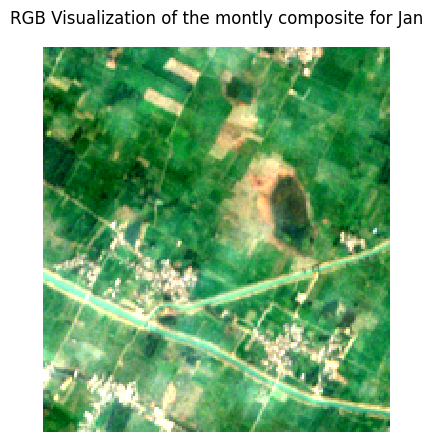

In [26]:
#Plot...
fig, ax = plt.subplots(1, 1)
fig.set_size_inches(5,5)
january_monthly.sel(band=['red', 'green', 'blue']).plot.imshow(
    ax=ax,
    robust=True)
ax.set_title('RGB Visualization of the montly composite for Jan')
ax.set_axis_off()
ax.set_aspect('equal')
plt.show()